SetUp

In [1]:
# pip install opencv-python matplotlib numpy pandas scikit-image

In [2]:
import json
import pickle
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.segmentation import mark_boundaries, slic

%config InlineBackend.figure_formats = ['jpeg']

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FRAMES_DIR = ROOT / 'data' / 'raw' / 'frames'
REF_DIR = ROOT / 'data' / 'annotations' / 'references'
ROI_DIR = ROOT / 'data' / 'annotations' / 'roi'
MASK_DIR = ROOT / 'data' / 'annotations' / 'masks'
OUT_PKL = ROOT / 'data' / 'processed' / 'dataset_seg.pkl'

FRAME_W, FRAME_H = 1920, 1080   # aligned frames and references
SEG_W, SEG_H = 960, 540         # masks and the dataset are half size
FLOOR, MOTOR, IGNORE = 0, 1, 255
CLASS_NAMES = {FLOOR: 'floor', MOTOR: 'motorcycle', IGNORE: 'ignore'}
CLASS_COLORS = {FLOOR: (0, 200, 0), MOTOR: (0, 0, 230), IGNORE: (150, 150, 150)}   # BGR: green, red, gray

print('project folder:', ROOT)

project folder: C:\Users\ASUS\.vscode\pcd\project-akhir


Step 1: Frames and Labeling Progress

In [3]:
frames_index = pd.read_csv(FRAMES_DIR / 'frames_index.csv', dtype={'date': str})
frames_index['has_mask'] = [(MASK_DIR / f.replace('.jpg', '.png')).exists() for f in frames_index['frame']]

progress = frames_index.groupby('video_id').agg(weather=('weather', 'first'), who=('who', 'first'),
                                                frames=('frame', 'count'), masks=('has_mask', 'sum'))
progress['roi'] = [(ROI_DIR / f'{v}.json').exists() for v in progress.index]

print('frames      :', len(frames_index))
print('with ROI    :', int(progress['roi'].sum()), 'of', len(progress), 'videos')
print('with a mask :', int(frames_index['has_mask'].sum()), 'of', len(frames_index), 'frames')
progress

frames      : 92
with ROI    : 12 of 12 videos
with a mask : 3 of 92 frames


,weather,who,frames,masks,roi
video_id,,,,,
20261103_afternoon_keiza,sunny,keiza,4,0,True
20261103_morning_keiza,sunny,keiza,10,0,True
20261104_afternoon_dinda,sunny,dinda,9,3,True
20261104_evening_keiza,dusk,keiza,9,0,True
20261105_afternoon_dinda,sunny,dinda,4,0,True
20261106_afternoon_keiza,cloudy,keiza,9,0,True
20261106_afternoonrain_keiza,rain,keiza,9,0,True
20261109_afternoonrain_tobi,rain,tobi,9,0,True
20261109_morning_dinda,sunny,dinda,3,0,True


label dibuat dalam dua langkah, keduanya oleh **orang yang merekam video nya**:

1. **roi, sekali per video** (±2 menit): `python src/pcd/draw_roi.py <video id>`. untuk video berikutnya bisa mulai dari roi video lain: `python src/pcd/draw_roi.py <video id> <video id lain>`, lalu digeser dengan `i/j/k/l` dan `[` / `]`.
2. **mask, per frame** (±1–3 menit): `python src/pcd/label_masks.py <nama atau tanggal>`, misalnya `python src/pcd/label_masks.py keiza`.

tabel di atas menunjukkan video mana yang sudah punya roi dan berapa frame yang sudah punya mask.

Step 2: ROI, Ground Rectangle and One Motorcycle

In [4]:
def load_roi(vid):
    data = json.loads((ROI_DIR / f'{vid}.json').read_text(encoding='utf-8'))
    s = SEG_W / FRAME_W   # clicked on the 1920 reference, used on 960 masks
    roi = {'roi': [np.float32(p) * s for p in data['roi']],
           'ground': np.float32(data['ground']) * s,
           'motor': np.float32(data['motor']) * s}
    return roi


def roi_mask(roi):
    mask = np.zeros((SEG_H, SEG_W), np.uint8)
    for poly in roi['roi']:
        cv.fillPoly(mask, [np.int32(poly)], 1)
    return mask


def draw_roi(img, roi):
    fill = img.copy()
    for poly in roi['roi']:
        cv.fillPoly(fill, [np.int32(poly)], (255, 200, 0))
    vis = cv.addWeighted(fill, 0.3, img, 0.7, 0)
    for poly in roi['roi']:
        cv.polylines(vis, [np.int32(poly)], True, (255, 200, 0), 2)
    cv.polylines(vis, [np.int32(roi['ground'])], True, (0, 255, 255), 2)   # ground rectangle: yellow
    cv.polylines(vis, [np.int32(roi['motor'])], True, (255, 0, 255), 2)    # one motorcycle: magenta
    return vis

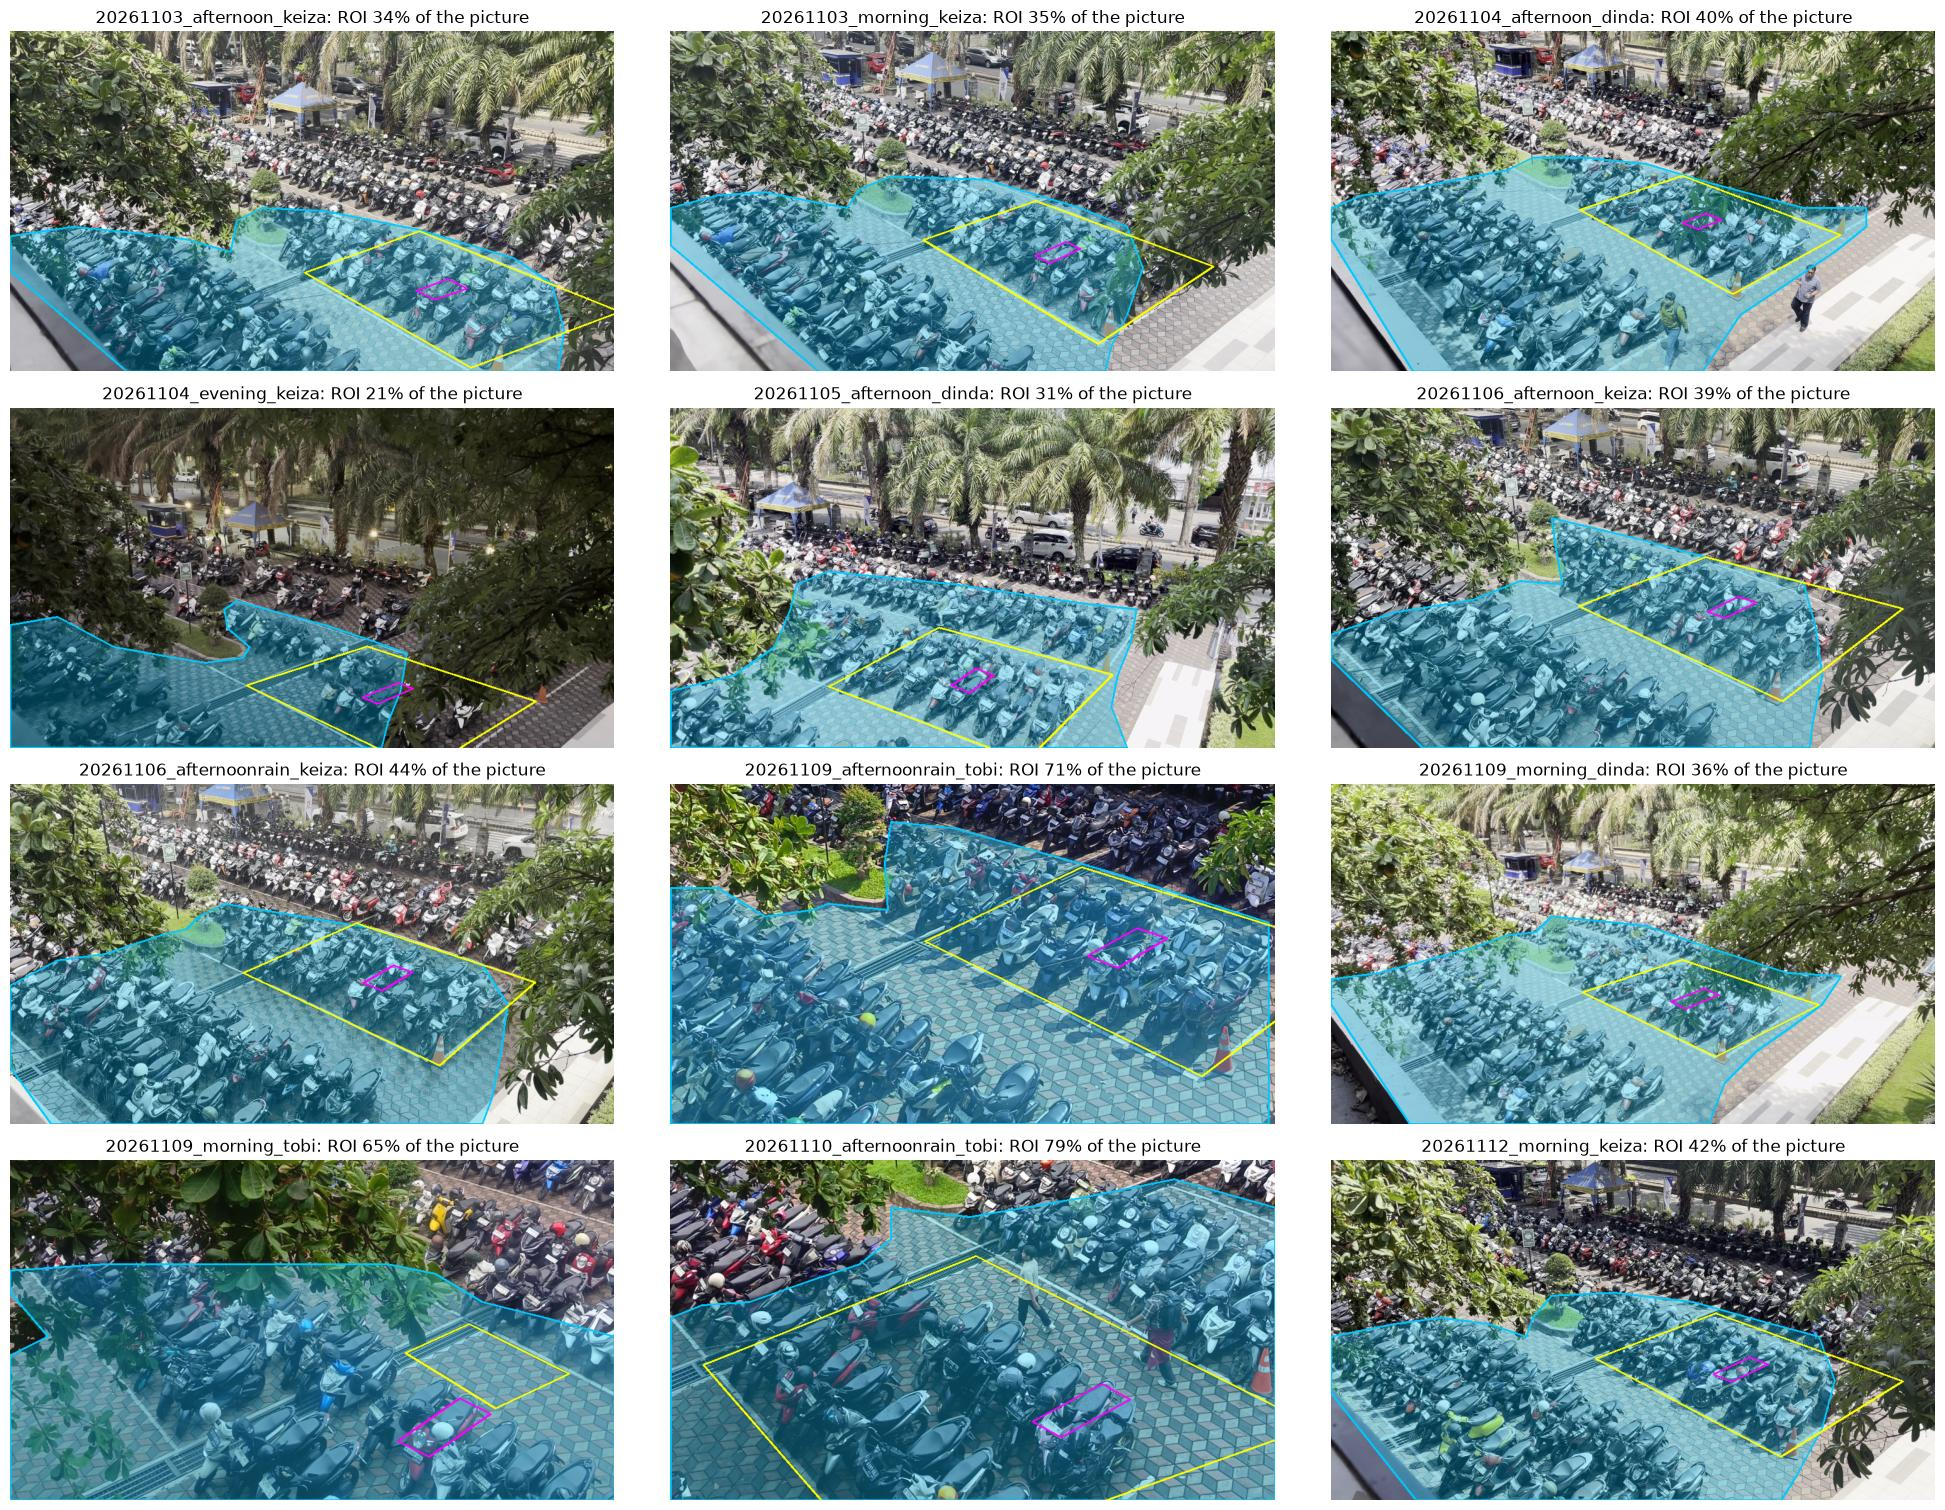

In [5]:
roi_videos = [v for v in progress.index if progress.loc[v, 'roi']]
assert len(roi_videos) > 0, 'no ROI yet: run  python src/pcd/draw_roi.py <video id>  first'

rois = {}
for v in roi_videos:
    rois[v] = load_roi(v)

cols = 3
rows = int(np.ceil(len(roi_videos) / cols))
plt.figure(figsize=(20, 3.8 * rows))
for k in range(len(roi_videos)):
    v = roi_videos[k]
    ref = cv.resize(cv.imread(str(REF_DIR / f'{v}.jpg')), (SEG_W, SEG_H), interpolation=cv.INTER_AREA)
    plt.subplot(rows, cols, k + 1)
    plt.imshow(draw_roi(ref, rois[v])[:, :, ::-1])
    plt.title(f"{v}: ROI {100 * roi_mask(rois[v]).mean():.0f}% of the picture")
    plt.axis('off')
plt.tight_layout()
plt.show()

untuk setiap video digambar tiga hal di atas frame referensi nya:

- **roi** (biru): area parkir yang dianalisis, yaitu baris parkir depan yang terlihat jelas. jalur jalan (lorong antar baris) **tidak** dimasukkan, karena lantai kosong di jalur bukan tempat parkir. pohon, baris belakang yang terlalu kecil dan area hitam bekas warp juga di luar roi.
- **ground rectangle** (kuning): 4 sudut sebuah persegi panjang besar di lantai, misalnya garis putih blok parkir depan. ini dipakai untuk menghitung bird's-eye view di step 3.
- **satu motor** (magenta): 4 sudut ruang yang dipakai **satu motor yang parkir**, dari sisi motor ini sampai sisi motor sebelah nya, depan sampai belakang. luas nya adalah satuan untuk menghitung jumlah ruang kosong.

semua frame di dalam satu video sudah berimpit dengan referensi nya, jadi ketiga gambar ini cukup dibuat **sekali per video**.

Step 3: Bird's-Eye View

In [6]:
BEV_SIZE = 600   # longest side of the bird's-eye picture


def bev_homography(roi):
    # ground rectangle -> unit square, then scale and shift so the whole ROI fits in the picture
    square = np.float32([[0, 0], [1, 0], [1, 1], [0, 1]])
    H = cv.getPerspectiveTransform(roi['ground'], square)
    pts = np.concatenate(roi['roi']).reshape(-1, 1, 2)
    bev = cv.perspectiveTransform(pts, H).reshape(-1, 2)
    x0, y0 = bev.min(axis=0)
    x1, y1 = bev.max(axis=0)
    scale = BEV_SIZE / max(x1 - x0, y1 - y0)
    T = np.float64([[scale, 0, -x0 * scale], [0, scale, -y0 * scale], [0, 0, 1]])
    size = (int(np.ceil((x1 - x0) * scale)) + 1, int(np.ceil((y1 - y0) * scale)) + 1)
    return T @ H, size


def prepare_video(roi, fit):
    H, size = bev_homography(roi)
    roi_bev = cv.warpPerspective(roi_mask(roi), H, size, flags=cv.INTER_NEAREST)
    motor_bev = cv.perspectiveTransform(roi['motor'].reshape(-1, 1, 2), H).reshape(-1, 2)
    motor_area = cv.contourArea(motor_bev)

    # structuring element = footprint of one motorcycle in the bird's-eye view, shrunk by FIT
    shape = (motor_bev - motor_bev.mean(axis=0)) * fit
    shape = shape - shape.min(axis=0)
    kernel = np.zeros((int(np.ceil(shape[:, 1].max())) + 1, int(np.ceil(shape[:, 0].max())) + 1), np.uint8)
    cv.fillPoly(kernel, [np.int32(np.round(shape))], 1)

    return {'roi_mask': roi_mask(roi), 'H': H, 'size': size, 'roi_bev': roi_bev,
            'motor_bev': motor_bev, 'motor_area': motor_area, 'kernel': kernel}

homography (picture -> bird's-eye):
[[    3.2718    -2.3811   904.8012]
 [    2.129      6.0707 -1972.973 ]
 [    0.0018     0.0056     1.    ]]
bird's-eye size  : (601, 569)
one motorcycle   : 985 px in the bird's-eye view
ROI              : 195114 px -> room for about 198 motorcycles


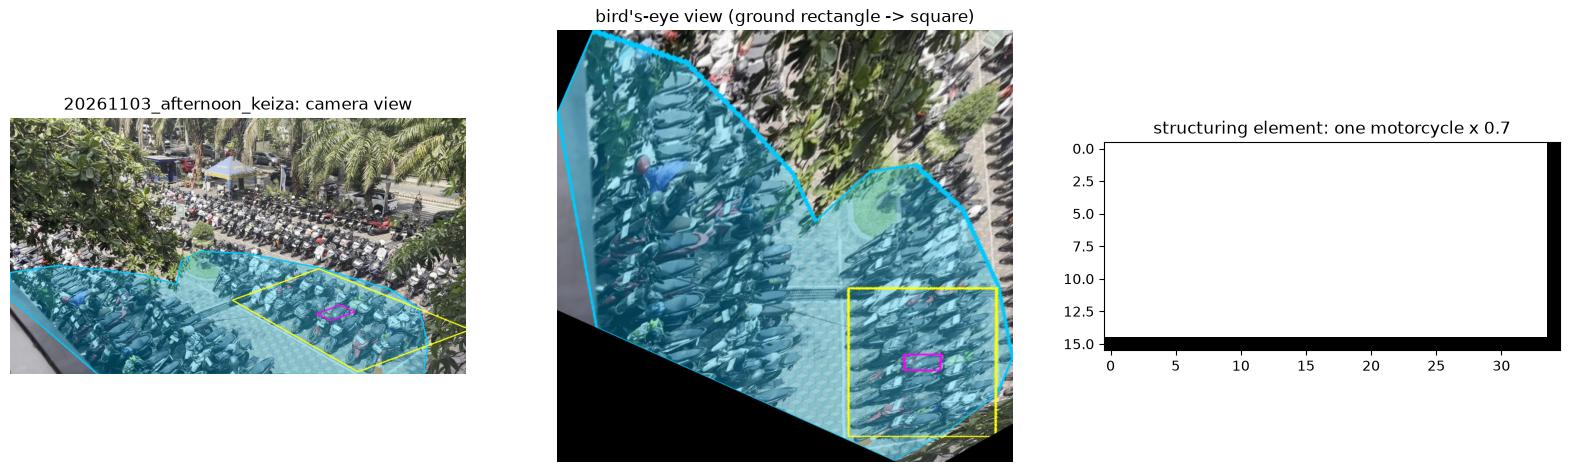

In [7]:
FIT = 0.7   # a gap counts as free when 70% of a motorcycle footprint fits in it

geo = {}
for v in roi_videos:
    geo[v] = prepare_video(rois[v], FIT)

DEMO_VID = roi_videos[0]
g = geo[DEMO_VID]
ref = cv.resize(cv.imread(str(REF_DIR / f'{DEMO_VID}.jpg')), (SEG_W, SEG_H), interpolation=cv.INTER_AREA)
ref_bev = cv.warpPerspective(draw_roi(ref, rois[DEMO_VID]), g['H'], g['size'])

np.set_printoptions(precision=4, suppress=True)
print('homography (picture -> bird\'s-eye):')
print(g['H'])
print("bird's-eye size  :", g['size'])
print('one motorcycle   :', round(g['motor_area']), "px in the bird's-eye view")
print('ROI              :', int(g['roi_bev'].sum()), "px -> room for about", round(g['roi_bev'].sum() / g['motor_area']), 'motorcycles')

plt.figure(figsize=(20, 7))
plt.subplot(1, 3, 1)
plt.imshow(draw_roi(ref, rois[DEMO_VID])[:, :, ::-1])
plt.title(f'{DEMO_VID}: camera view')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(ref_bev[:, :, ::-1])
plt.title("bird's-eye view (ground rectangle -> square)")
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(g['kernel'], cmap='gray', vmin=0, vmax=1)
plt.title(f'structuring element: one motorcycle x {FIT}')
plt.show()

kamera melihat lantai dari samping atas, jadi **satu piksel di bagian jauh mewakili luas lantai yang lebih besar** daripada satu piksel di bagian dekat. kalau luas dihitung langsung dari piksel kamera, lantai kosong di belakang akan terhitung terlalu kecil. karena itu mask diubah dulu ke **bird's-eye view** (tampilan dari atas) dengan homography: 4 sudut ground rectangle dipetakan ke 4 sudut persegi dengan `cv.getPerspectiveTransform`, lalu `cv.warpPerspective` memindahkan semua piksel lantai. di tampilan ini setiap piksel mewakili luas lantai yang sama.

ukuran asli ground rectangle (dalam meter) tidak perlu diketahui. memetakan persegi panjang ke persegi hanya menambah skala yang berbeda di sumbu x dan y, dan skala seperti itu mengalikan **semua** luas dengan angka yang sama. jadi perbandingan luas lantai ÷ luas satu motor tidak berubah. cara mengecek nya: garis putih yang sejajar di dunia nyata harus terlihat sejajar di bird's-eye view (bisa dilihat dengan tombol `v` di `draw_roi.py`).

Step 4: Superpixels (SLIC)

In [8]:
def video_of(frame_name):
    return frame_name.rsplit('_t', 1)[0]   # 20261104_evening_keiza_t015.jpg -> 20261104_evening_keiza


def superpixels(img, roi, size):
    n_segments = max(1, int(np.sum(roi > 0) / size ** 2))
    return slic(img[:, :, ::-1], n_segments=n_segments, compactness=10, start_label=1, mask=roi > 0)

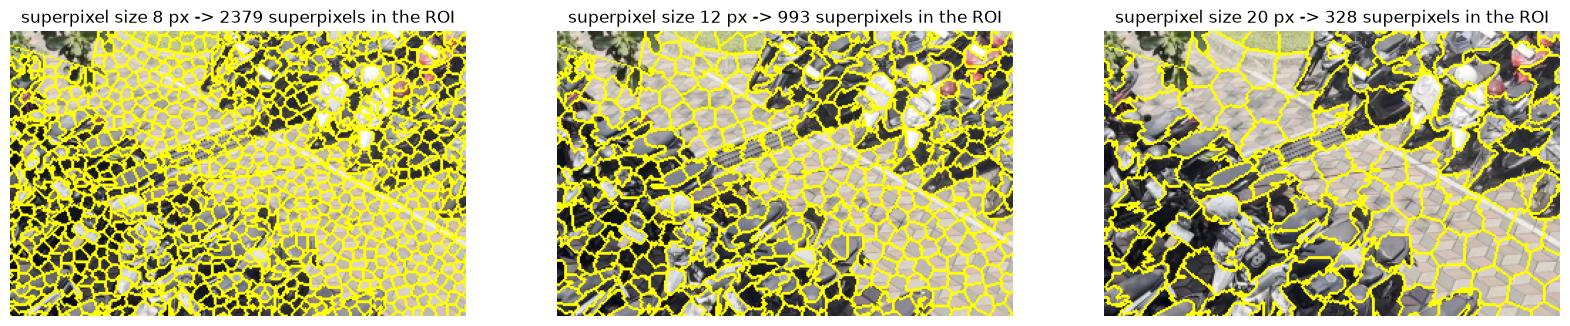

In [9]:
labeled = frames_index[frames_index['video_id'].isin(roi_videos)].reset_index(drop=True)
DEMO_FRAME = labeled['frame'][0]
img = cv.resize(cv.imread(str(FRAMES_DIR / DEMO_FRAME)), (SEG_W, SEG_H), interpolation=cv.INTER_AREA)
demo_roi = geo[video_of(DEMO_FRAME)]['roi_mask']

ys, xs = np.where(demo_roi > 0)
cy, cx = int(ys.mean()), int(xs.mean())
y0, x0 = max(0, cy - 100), max(0, cx - 160)   # zoom on the middle of the ROI

plt.figure(figsize=(20, 5))
for k, size in enumerate([8, 12, 20]):
    sp = superpixels(img, demo_roi, size)
    vis = mark_boundaries(img[:, :, ::-1], sp, color=(1, 1, 0))
    plt.subplot(1, 3, k + 1)
    plt.imshow(vis[y0:y0 + 200, x0:x0 + 320])
    plt.title(f'superpixel size {size} px -> {sp.max()} superpixels in the ROI')
    plt.axis('off')
plt.show()

mewarnai ratusan ribu piksel satu per satu tidak mungkin, jadi frame dipecah dulu menjadi **superpixel** dengan **slic** (simple linear iterative clustering). slic adalah k-means pada 5 dimensi (l, a, b, x, y): setiap piksel masuk ke pusat cluster terdekat dari segi warna **dan** posisi, jadi hasil nya potongan kecil yang warna nya seragam dan batas nya mengikuti tepi benda (tepi motor, garis putih, sambungan ubin). parameter `compactness` mengatur seberapa kotak bentuk nya: makin besar, makin mirip grid biasa.

di `label_masks.py` satu klik mewarnai satu superpixel, dan menahan klik sambil menggeser mouse mewarnai banyak superpixel sekaligus. ukuran default 12 px (di citra 960 × 540) cukup kecil untuk mengikuti bentuk motor, dan bisa diubah dengan `[` / `]` kalau ada bagian yang perlu lebih detail.

Step 5: Mask Labeling

In [10]:
def overlay_mask(img, mask):
    color = np.zeros_like(img)
    for cls in CLASS_COLORS:
        color[mask == cls] = CLASS_COLORS[cls]
    return cv.addWeighted(color, 0.45, img, 0.55, 0)


masks = {}
for f in labeled['frame']:
    p = MASK_DIR / f.replace('.jpg', '.png')
    if p.exists():
        masks[f] = cv.imread(str(p), cv.IMREAD_GRAYSCALE)
assert len(masks) > 0, 'no masks yet: run  python src/pcd/label_masks.py  first'

stats = []
for f in masks:
    m = masks[f]
    inside = np.sum(m != IGNORE)
    stats.append([f, video_of(f), 100 * np.sum(m == FLOOR) / inside, 100 * np.sum(m == MOTOR) / inside,
                  100 * np.mean(m == IGNORE)])
stats = pd.DataFrame(stats, columns=['frame', 'video_id', 'floor % of ROI', 'motor % of ROI', 'ignore % of picture'])

print('labeled frames:', len(masks))
print('pixels  floor:', sum(int(np.sum(m == FLOOR)) for m in masks.values()),
      '| motorcycle:', sum(int(np.sum(m == MOTOR)) for m in masks.values()))
stats.groupby('video_id')[['floor % of ROI', 'motor % of ROI']].mean().round(1)

labeled frames: 3
pixels  floor: 197289 | motorcycle: 378274


,floor % of ROI,motor % of ROI
video_id,,
20261104_afternoon_dinda,34.3,65.7


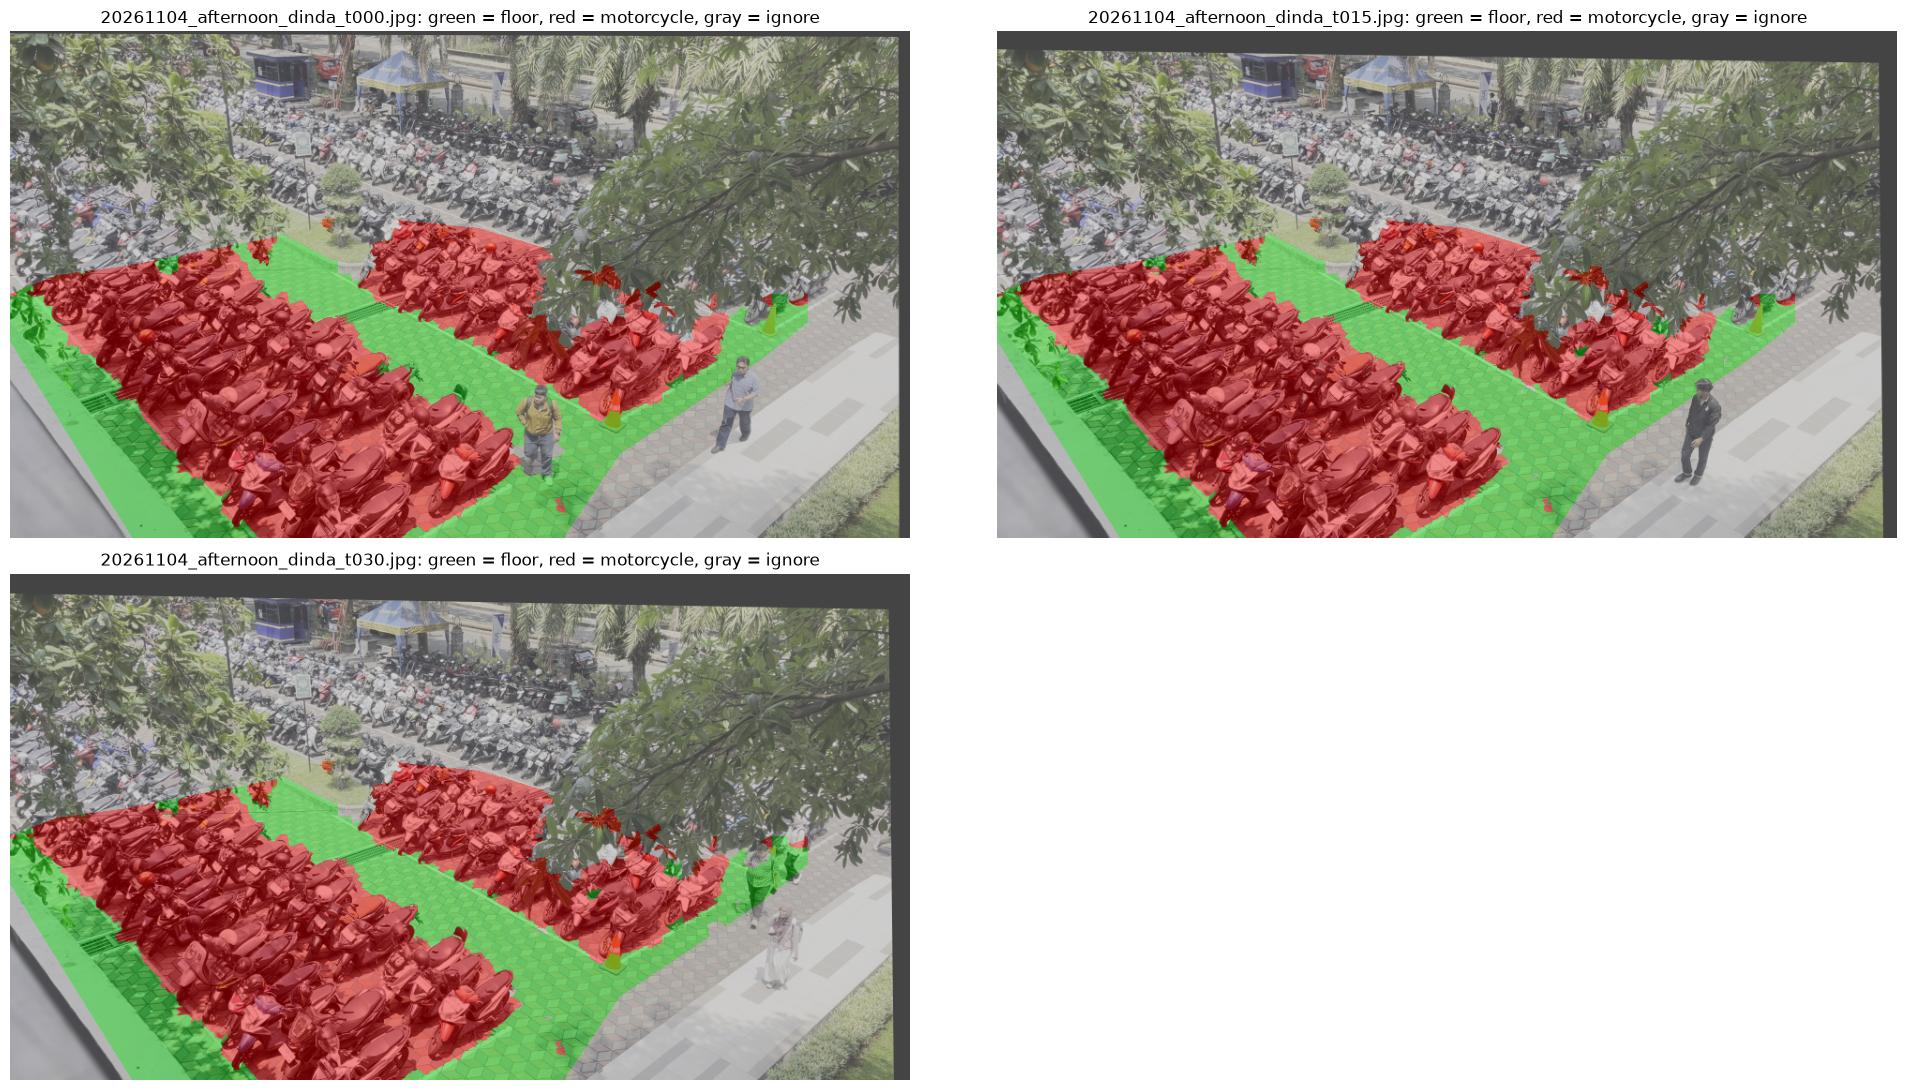

In [11]:
show = list(masks)[::max(1, len(masks) // 4)][:4]

plt.figure(figsize=(20, 11))
for k in range(len(show)):
    f = show[k]
    img_k = cv.resize(cv.imread(str(FRAMES_DIR / f)), (SEG_W, SEG_H), interpolation=cv.INTER_AREA)
    plt.subplot(2, 2, k + 1)
    plt.imshow(overlay_mask(img_k, masks[f])[:, :, ::-1])
    plt.title(f'{f}: green = floor, red = motorcycle, gray = ignore')
    plt.axis('off')
plt.tight_layout()
plt.show()

setiap frame diberi mask 960 × 540 dengan tiga kelas:

- **0 = lantai (floor)**: paving yang terlihat di dalam roi, termasuk garis putih dan bayangan di lantai.
- **1 = motor (motorcycle)**: badan motor, termasuk helm dan barang yang menempel di motor.
- **255 = ignore**: di luar roi, area hitam bekas warp (otomatis), orang yang lewat, cone, ranting atau daun yang menutupi lantai, dan semua bagian yang tidak bisa dinilai. piksel ignore tidak ikut training maupun evaluasi.

di dalam satu video, frame berikutnya mulai dari mask frame sebelumnya karena semua frame nya sudah berimpit, jadi yang perlu diwarnai hanya motor yang datang atau pergi. mask disimpan di `data/annotations/masks/<frame>.png` (nilai piksel 0, 1, 255).

Step 6: Free Spaces from the Mask

In [12]:
def count_free_spaces(mask, g):
    floor = (mask == FLOOR).astype(np.uint8)
    floor_bev = cv.warpPerspective(floor, g['H'], g['size'], flags=cv.INTER_NEAREST) * g['roi_bev']

    # opening with the motorcycle footprint removes gaps that are too small for a motorcycle
    usable = cv.morphologyEx(floor_bev, cv.MORPH_OPEN, g['kernel'])

    n, labels, comp_stats, _ = cv.connectedComponentsWithStats(usable)
    free = 0
    for c in range(1, n):
        free += max(1, int(round(comp_stats[c, cv.CC_STAT_AREA] / g['motor_area'])))
    return free, floor_bev, usable

frame                 : 20261104_afternoon_dinda_t000.jpg
floor (bird's-eye)   : 48453 px = 54.0 motorcycles of area
usable after opening  : 38268 px
free spaces           : 43


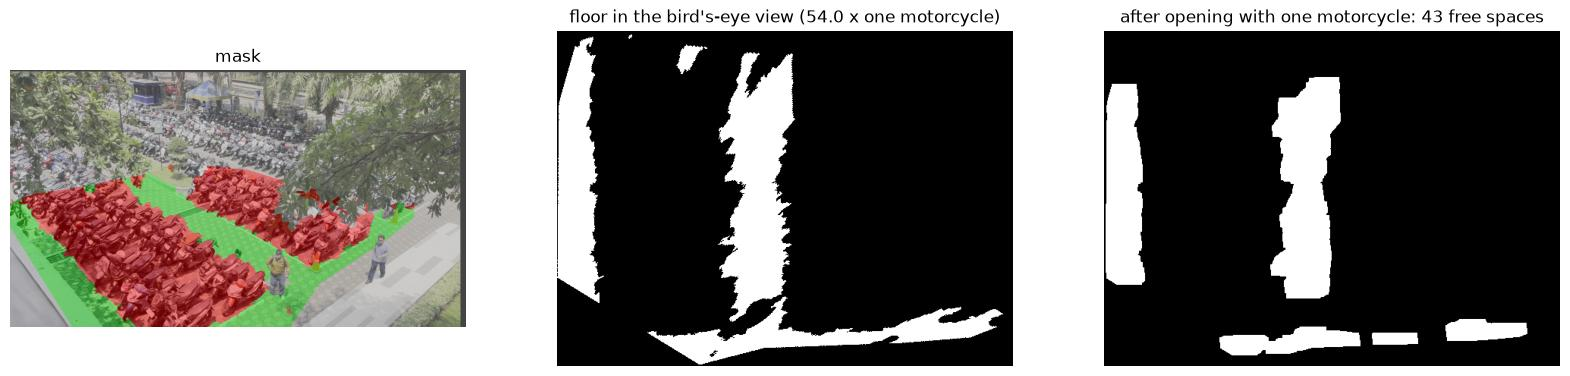

In [13]:
f = list(masks)[0]
g = geo[video_of(f)]
free, floor_bev, usable = count_free_spaces(masks[f], g)
img_f = cv.resize(cv.imread(str(FRAMES_DIR / f)), (SEG_W, SEG_H), interpolation=cv.INTER_AREA)

print('frame                 :', f)
print('floor (bird\'s-eye)   :', int(floor_bev.sum()), 'px =', round(floor_bev.sum() / g['motor_area'], 1), 'motorcycles of area')
print('usable after opening  :', int(usable.sum()), 'px')
print('free spaces           :', free)

plt.figure(figsize=(20, 6))
plt.subplot(1, 3, 1)
plt.imshow(overlay_mask(img_f, masks[f])[:, :, ::-1])
plt.title('mask')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(floor_bev, cmap='gray')
plt.title(f"floor in the bird's-eye view ({floor_bev.sum() / g['motor_area']:.1f} x one motorcycle)")
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(usable, cmap='gray')
plt.title(f'after opening with one motorcycle: {free} free spaces')
plt.axis('off')
plt.show()

jumlah ruang kosong dihitung dalam 3 langkah:

1. piksel lantai di dalam roi dipindah ke **bird's-eye view** (`cv.warpPerspective` dengan interpolasi nearest supaya nilai nya tetap 0 / 1).
2. **morphological opening** dengan structuring element berbentuk tapak satu motor (dikecilkan dengan `FIT = 0.7`). opening = erosi lalu dilasi: lantai yang lebih sempit dari tapak motor (celah di antara motor yang parkir, garis lantai yang tipis) hilang, dan yang tersisa hanya area yang benar-benar muat untuk motor. faktor 0.7 dipakai karena sebagian lantai yang kosong tertutup badan motor di sebelah nya (kamera melihat dari samping atas), jadi lantai yang terlihat lebih kecil dari ruang sebenarnya.
3. setiap area yang tersisa (connected component) dibagi dengan **luas satu motor** dan dibulatkan, minimal 1 karena area itu lolos opening. jumlah nya adalah **perkiraan ruang kosong**.

perhitungan yang sama dipakai untuk mask hasil prediksi model nanti, jadi error nya bisa diukur sebagai **mae jumlah ruang kosong** terhadap mask label.

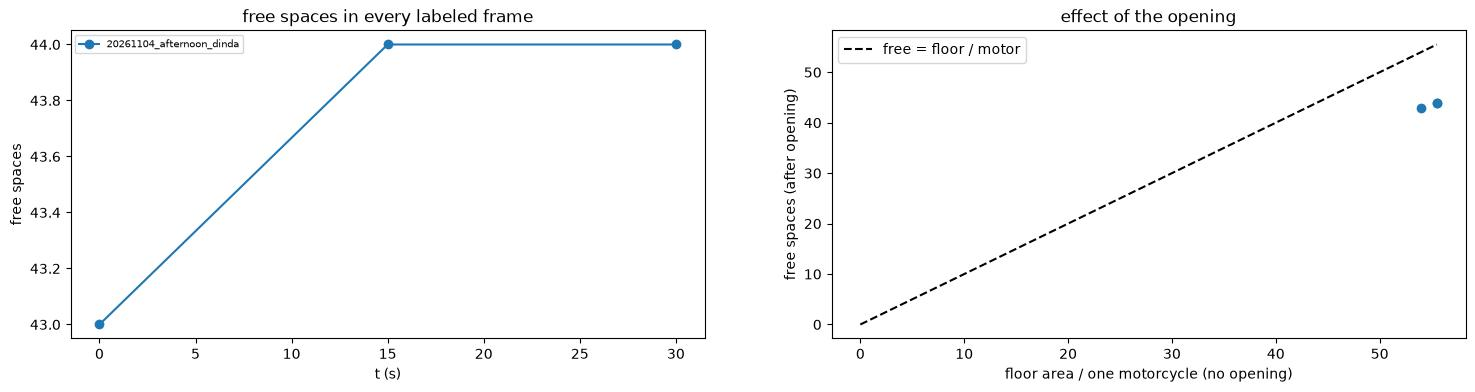

In [14]:
free_list, floor_list = [], []
for f in stats['frame']:
    free, floor_bev, usable = count_free_spaces(masks[f], geo[video_of(f)])
    free_list.append(free)
    floor_list.append(floor_bev.sum() / geo[video_of(f)]['motor_area'])
stats['floor / motor'] = np.round(floor_list, 1)
stats['free spaces'] = free_list
stats['t_sec'] = [int(f.rsplit('_t', 1)[1][:3]) for f in stats['frame']]

plt.figure(figsize=(18, 4))
plt.subplot(1, 2, 1)
for v, part in stats.groupby('video_id'):
    plt.plot(part['t_sec'], part['free spaces'], 'o-', label=v)
plt.xlabel('t (s)')
plt.ylabel('free spaces')
plt.title('free spaces in every labeled frame')
plt.legend(fontsize=7)
plt.subplot(1, 2, 2)
plt.scatter(stats['floor / motor'], stats['free spaces'])
plt.plot([0, stats['floor / motor'].max()], [0, stats['floor / motor'].max()], 'k--', label='free = floor / motor')
plt.xlabel('floor area / one motorcycle (no opening)')
plt.ylabel('free spaces (after opening)')
plt.title('effect of the opening')
plt.legend()
plt.show()

Step 7: Split by Day and Build the Dataset

In [15]:
TEST_DAYS = ['20261104', '20261112']   # afternoon + evening (dusk) + morning, never used for training
VAL_DAYS = ['20261105', '20261110']    # for choosing thresholds and hyperparameters


def split_of(date):
    if date in TEST_DAYS:
        return 'test'
    if date in VAL_DAYS:
        return 'val'
    return 'train'


meta = labeled[labeled['frame'].isin(list(masks))].reset_index(drop=True)
meta = meta[['frame', 'video_id', 'date', 'time', 'weather', 'who', 't_sec']].copy()
meta['split'] = [split_of(d) for d in meta['date']]

# while only a few frames are labeled, some splits are still empty: then (temporarily) spread the labeled
# frames over train / val / test in time order, so the next notebooks can already run. NOT a fair split!
TEMP_SPLIT = any(np.sum(meta['split'] == s) == 0 for s in ['train', 'val', 'test'])
if TEMP_SPLIT:
    order = meta.sort_values(['video_id', 't_sec']).index
    meta.loc[order, 'split'] = [['train', 'val', 'test'][min(2, i * 3 // len(order))] for i in range(len(order))]
    print('WARNING: not enough labeled days yet -> temporary split by time order, only to test the pipeline')
meta = meta.merge(stats[['frame', 'floor % of ROI', 'free spaces']], on='frame')

X, Y = [], []
for f in meta['frame']:
    X.append(cv.resize(cv.imread(str(FRAMES_DIR / f)), (SEG_W, SEG_H), interpolation=cv.INTER_AREA))
    Y.append(masks[f])
X, Y = np.stack(X), np.stack(Y)

print('X:', X.shape, X.dtype, '(frames, height, width, BGR)')
print('Y:', Y.shape, Y.dtype, '(0 floor, 1 motorcycle, 255 ignore)')
meta.groupby('split').agg(frames=('frame', 'count'), days=('date', 'unique'), weather=('weather', 'unique'))

X: (3, 540, 960, 3) uint8 (frames, height, width, BGR)
Y: (3, 540, 960) uint8 (0 floor, 1 motorcycle, 255 ignore)


,frames,days,weather
split,,,
test,1,[20261104],[sunny]
train,1,[20261104],[sunny]
val,1,[20261104],[sunny]


In [16]:
OUT_PKL.parent.mkdir(parents=True, exist_ok=True)
with open(OUT_PKL, 'wb') as f:
    pickle.dump({'X': X, 'Y': Y, 'meta': meta, 'geo': geo, 'fit': FIT,
                 'classes': CLASS_NAMES,
                 'info': 'X = aligned frames 960x540 BGR uint8 (no other PCD); Y = masks 0 floor, 1 motorcycle, '
                         '255 ignore; geo[video_id] = roi_mask, bird\'s-eye homography H, size, roi_bev, motor_area, '
                         'kernel; split by day in meta["split"], never randomly'}, f)

print('saved', OUT_PKL, f'({OUT_PKL.stat().st_size / 1e6:.0f} MB)')

saved C:\Users\ASUS\.vscode\pcd\project-akhir\data\processed\dataset_seg.pkl (16 MB)


train / val / test dibagi **per hari**, bukan acak. frame dari video yang sama hampir identik, jadi split acak akan memasukkan "kembaran" frame test ke data training dan skor nya jadi terlalu bagus. hari test (4 dan 12 november) berisi siang, sore (dusk) dan pagi dari dua perekam, hari validasi (5 dan 10 november) dipakai untuk memilih threshold dan hyperparameter, dan sisa nya untuk training.

`dataset_seg.pkl` berisi:
- `X`: frame 960 × 540 (bgr uint8, belum diberi preprocessing pcd), untuk eksperimen raw
- `Y`: mask 960 × 540 (0 lantai, 1 motor, 255 ignore)
- `meta`: frame, video, tanggal, waktu, cuaca, perekam, split, % lantai, jumlah ruang kosong (label)
- `geo`: per video, mask roi, homography bird's-eye, luas satu motor dan structuring element, supaya notebook berikutnya bisa menghitung jumlah ruang kosong dari mask prediksi dengan `count_free_spaces` yang sama